# 01 — Design: what is being estimated, and on what authority

Most applied questions about the real world do not come with a randomised trial. A state raises a
tax, a county lifts a wage floor, a firm opens a store — and the analyst is left with an
observational panel and asked for a *causal* number. This repository is built around that
situation, and this notebook is where the estimand and the identifying assumptions get written
down **before** any estimator runs.

## The two questions

| | Question | Design | Data |
|---|---|---|---|
| **A** | Does raising the minimum wage reduce teen employment in US counties? | Difference-in-differences, staggered adoption, many treated units | 500 counties x 2003-07 (`mpdta`) |
| **B** | Did California's Proposition 99 (1989, +25c cigarette excise) reduce per-capita cigarette sales? | Synthetic control, one treated unit, no comparable control | 39 states x 1970-2000 (`smoking`) |

These are deliberately opposite failure modes of naive analysis, not two flavors of the same
thing. In **A** there are plenty of controls and the danger is *which* controls you are allowed to
use: with staggered timing, later-treated counties are contaminated if compared against
earlier-treated ones. In **B** there is exactly one treated unit and the danger is *constructing*
the control at all: any single state picked by eye is a bad counterfactual, and averaging all 38
others ignores that states differ in level and trend.

## Estimands, stated precisely

**A.** `ATT(g, t)` = E[Y_t(1) - Y_t(0) | G = g], the average treatment effect in period `t` on the
subpopulation first treated in period `g`. Headline numbers are weighted averages over `(g, t)`
cells, weights being treated-unit counts. Never "the effect of the minimum wage" in the abstract.

**B.** `gap_it = Y_treated,it - Y_treated,it(0)` for `t >= 1989`, where the counterfactual is a
convex combination of donor states. Report the annual gap, the 2000 gap, and the cumulative gap
1989-2000 — never a single "effect size".

## Identifying assumptions, and whether they are testable

| Assumption | What it says | Testable? | Test used here |
|---|---|---|---|
| **Parallel trends** (A) | Absent treatment, treated and control counties' outcome *changes* would have moved alike | Partially | Pre-treatment coefficients in an event study; `ATT(g,t)` placebo cells for `t < g` |
| **No anticipation** (A) | Counties did not change employment before the law took effect | Partially | Coefficient at `t = g - 1` should be ~0 |
| **Control-group availability** (A) | Enough not-yet-treated units remain at every `(g, t)` | Yes | Cell counts printed per estimate |
| **Convex-hull / good pre-fit** (B) | The treated unit's pre-period history is reproducible from donors | Yes | Pre-treatment RMSPE, and the post/pre ratio |
| **SUTVA, no spillovers** (both) | One county's tax does not shift another's sales | No | Assumed; discussed as a limitation |
| **No simultaneous shocks** (both) | Nothing else hit only the treated unit at the same date | Weakly | In-time placebos on the pre-period |

The first four are checked in the notebooks that follow. The last two cannot be, and that is
reported as a limitation rather than glossed.

## What this notebook does

Loads both panels, verifies the structure every downstream estimator silently assumes, and prints
the descriptive facts that decide which designs are even available.

In [1]:
from pathlib import Path
import sys

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
FIGS = REPO / "report" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 25)

from cid import io as cidio, viz
from IPython.display import display, Image


def show(name, width=780):
    """Display a figure the analysis just wrote, so output is deterministic across backends."""
    path = FIGS / name
    if path.exists():
        display(Image(filename=str(path), embed=True, width=width))
    else:
        print("missing figure:", path)

In [2]:
from cid import io as cidio
from cid.did import diagnostics

mpdta = cidio.load_mpdta()
smoking = cidio.load_smoking()

print("mpdta  ", mpdta.shape, list(mpdta.columns))
print("smoking", smoking.shape, list(smoking.columns))

mpdta   (2500, 9) ['year', 'countyreal', 'lpop', 'lemp', 'first_treat', 'treat', 'county', 'treated', 'g']
smoking (1209, 10) ['state', 'year', 'cigsale', 'lnincome', 'beer', 'age15to24', 'retprice', 'treated', 'g', 'lnprice']


## Integrity checks

`load_*` asserts a balanced unit-time grid with no duplicate keys. This is not ceremony: the
Callaway-Sant'Anna machinery reads a unit's value at period `g-1` from a pivot table, so a missing
baseline silently drops that whole cohort-period cell, and an unbalanced grid changes the weighting
without any error being raised.

In [3]:
for name, df, idc, oc in [("mpdta", mpdta, "countyreal", "lemp"), ("smoking", smoking, "state", "cigsale")]:
    print("=" * 20, name)
    for k, v in diagnostics.summary(df, id_col=idc, outcome=oc).items():
        print(f"  {k:16s} {v}")
    print(f"  {'missing cells':16s} {int(df[idc].isna().sum())}")

==================== mpdta
  n_units          500
  n_periods        5
  period_range     (2003, 2007)
  n_never_treated  309
  n_treated        191
  cohorts          {2004: 20, 2006: 40, 2007: 131}
  outcome_sd       1.508781175310537
  missing cells    0
==================== smoking
  n_units          39
  n_periods        31
  period_range     (1970, 2000)
  n_never_treated  38
  n_treated        1
  cohorts          {1989: 1}
  outcome_sd       32.76740405539667
  missing cells    0


### The structure that drives everything downstream

Minimum wage: three treated cohorts of very unequal size, and a large never-treated group.
Prop 99: a single treated unit. The following two cells make that concrete.

In [4]:
mpdta.groupby("g", dropna=False).size()

g
2004.0     100
2006.0     200
2007.0     655
inf       1545
dtype: int64

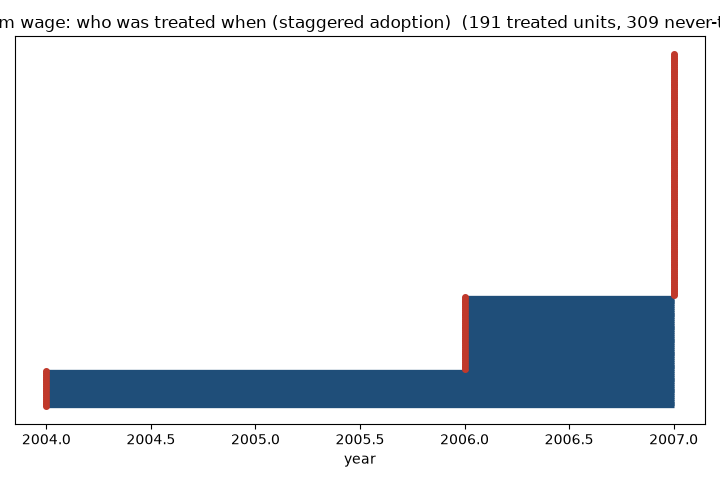

In [5]:
from cid import viz

viz.cohort_gantt(mpdta, "Minimum wage: who was treated when (staggered adoption)",
                 path=FIGS / "fig2_gantt.png")
show("fig2_gantt.png")

Read the Gantt before touching an estimator. The 2004 cohort has 20 counties and four
post-periods; the 2007 cohort has 131 counties and one post-period. A single pooled "ATT" is
therefore an average over very different amounts of exposure to treatment — which is exactly why a
static two-way fixed effects regression quietly gives large weights to comparisons between
already-treated units.

For Prop 99, the treated unit is unique and the outcome is complete for all 1,209 state-years.

In [6]:
sel = smoking[smoking.state.isin(["California", "Utah", "Nevada", "Colorado", "Ohio"])]
sel.pivot_table(index="year", columns="state", values="cigsale").round(1).loc[[1970, 1980, 1988, 1989, 1995, 2000]]

state,California,Colorado,Nevada,Ohio,Utah
year,,,,,
1970,123.0,124.8,189.5,121.6,65.5
1980,120.2,131.0,177.7,133.5,74.8
1988,90.1,94.6,141.9,122.4,55.0
1989,82.4,88.8,137.9,118.6,57.0
1995,56.4,85.4,100.9,111.7,52.0
2000,41.6,73.0,93.2,99.9,40.7


Look at the levels and the slopes separately. In 1988 California sits at 90.1 packs — nowhere near
Utah's 55.0, far below Nevada's 141.9 — so no single donor is a control and neither is the 38-state
average. By 2000 it has fallen to 41.6 while Nevada is still at 93.2, but Utah, which was 35
packs *below* California in 1988, ends at 40.7, essentially level with it. Utah's whole path is flatter
(-0.5 packs a year) than California's (-1.8), which is the kind of donor the optimiser likes for the
early years and then has to be offset against.

The consequence for anything built on matching: a method that matches on 1988 levels alone picks the
wrong counterfactual, and a method that matches on levels *and slope* has to be checked for whether
the chosen donors are similar in the ways that matter or merely numerically convenient. Notebook 03
finds the weight landing on half a dozen states — Utah 38%, Montana 27%, Nevada 19% — and that
Nevada, which falls 3.8 packs a year against California's 1.8, supplies close to half of the
synthetic counterfactual's pre-period decline. The counterfactual inherits its downward slope from
the steepest donor it is allowed to use.

## Plan for the remaining notebooks

1. **02** — estimate A four ways: naive static TWFE, dynamic event study with a pre-trend test,
   Callaway-Sant'Anna group-time ATT, Sun-Abraham interaction weights. Show where the naive version
   is wrong rather than hiding it.
2. **03** — estimate B with synthetic control: feature matching vs full trajectory matching,
   selected on pre-period fit; in-space placebos for a permutation p-value; in-time placebos as a
   falsification test.
3. **04** — specification curve and sensitivity: leave-one-donor-out stability, control-rule choice,
   estimator choice; then the decision memo.